<a href="https://colab.research.google.com/github/Hrishi-7899/bis_lab/blob/main/WEEK5_gray_wolf_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Optimal Solar Panel Angle: 29.98 degrees
Maximum Power Output: 100.0


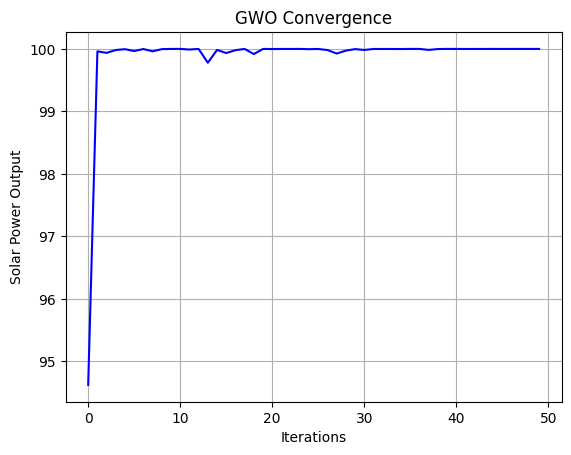

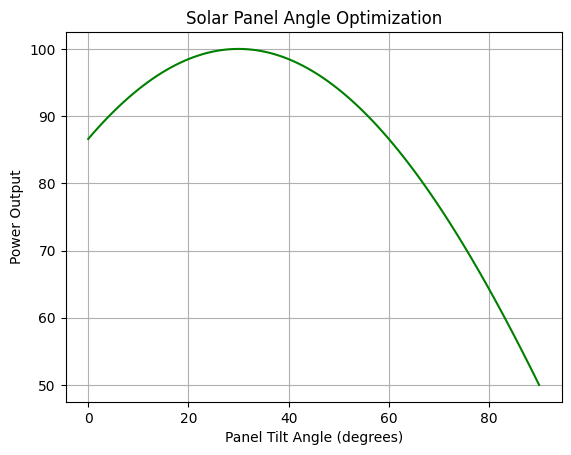

In [6]:

import numpy as np
import matplotlib.pyplot as plt

# Fitness function: maximize solar power
def fitness(angle):
    return 100 * np.cos(np.radians(angle - 30))

# Parameters
n = 10
iterations = 50

# Initialize wolves (panel angles)
wolves = np.random.uniform(0, 90, n)

best_values = []

# GWO algorithm
for t in range(iterations):

    scores = fitness(wolves)

    # Select best three wolves
    idx = np.argsort(scores)[::-1]

    alpha = wolves[idx[0]]
    beta = wolves[idx[1]]
    delta = wolves[idx[2]]

    a = 2 - 2*t/iterations

    # Update positions
    for i in range(n):

        X = []

        for leader in [alpha, beta, delta]:

            r1 = np.random.rand()
            r2 = np.random.rand()

            A = 2*a*r1 - a
            C = 2*r2

            D = abs(C*leader - wolves[i])

            new_position = leader - A*D

            X.append(new_position)

        wolves[i] = np.mean(X)
        wolves[i] = np.clip(wolves[i], 0, 90)

    best_values.append(fitness(alpha))

# Final result
best_angle = wolves[np.argmax(fitness(wolves))]

print("Optimal Solar Panel Angle:",
      round(best_angle, 2), "degrees")
print("Hrishikesh shet(1WN24CS120)")

print("Maximum Power Output:",
      round(fitness(best_angle), 2))

# Graph 1: Convergence
plt.plot(best_values, color='blue')
plt.xlabel("Iterations")
plt.ylabel("Solar Power Output")
plt.title("GWO Convergence")
plt.grid()
plt.show()

# Graph 2: Power vs Angle
angles = np.linspace(0, 90, 100)
power = fitness(angles)

plt.plot(angles, power, color='green')
plt.xlabel("Panel Tilt Angle (degrees)")
plt.ylabel("Power Output")
plt.title("Solar Panel Angle Optimization")
plt.grid()
plt.show()
